# Two different questions about a changing price

An invented series moves through $100,120,90,108,126$. It finishes 26% above its
start. A person looking only at that gain would miss the fall from 120 to 90.
How can we describe that fall, and how is it different from the variation in
successive returns?

This notebook teaches **drawdown**, a loss relative to the highest value already
seen, and **volatility**, a measure of how returns vary around their mean. You
need the simple returns and compounding from notebook 1, plus arithmetic and
squares. We will explain the statistical notation locally.

All prices are synthetic. These descriptive calculations omit dividends, fees,
taxes, and cash flows. They do not estimate the probability of a future loss or
recommend an investment.

## Setup

Use the repository environment: `uv sync --extra notebooks`. Open this file
in a Jupyter-capable editor using `.venv`, or execute both notebooks with
`uv run --extra notebooks python tools/verify_notebooks.py`. Run cells in order.

In [1]:
import math

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from quantchapter_returns import (
    annualized_volatility,
    drawdowns,
    maximum_drawdown,
    simple_returns,
    total_return,
)

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 110,
    }
)
prices = (100.0, 120.0, 90.0, 108.0, 126.0)
print(f"First-to-last price return: {total_return(prices):.2%}")

First-to-last price return: 26.00%


## Compare each value with the peak already reached

At observation 1, the highest price seen is 120. At observation 2, the price is
90, while that earlier peak remains 120. The loss relative to the peak is

$$\frac{90-120}{120}=\frac{-30}{120}=-0.25=-25\%.$$

At the next price, 108, the peak is still 120. The drawdown is
$108/120-1=-0.10$, or -10%. Reaching 126 creates a new peak and returns drawdown
to zero.

Write $H_t$ for the largest value observed up to and including observation $t$.
The running-peak rule and **drawdown** $D_t$ are

$$H_t=\max(P_0,\ldots,P_t),\qquad D_t=\frac{P_t}{H_t}-1.$$

The maximum symbol means choose the largest of the listed values. This package
reports drawdown as a signed number: zero at a peak and negative below it.
`maximum_drawdown` returns the most negative drawdown. Its name describes the
largest loss magnitude, not the numerically largest signed value.

In [2]:
underwater = drawdowns(prices)
print("Observation | Price | Drawdown")
for observation, (price, decline) in enumerate(zip(prices, underwater, strict=True)):
    print(f"{observation:11d} | {price:5.0f} | {decline:8.2%}")
print(f"Maximum drawdown (signed): {maximum_drawdown(prices):.2%}")
assert all(
    math.isclose(a, b, abs_tol=1e-14)
    for a, b in zip(underwater, (0.0, 0.0, -0.25, -0.10, 0.0), strict=True)
)

Observation | Price | Drawdown
          0 |   100 |    0.00%
          1 |   120 |    0.00%
          2 |    90 |  -25.00%
          3 |   108 |  -10.00%
          4 |   126 |    0.00%
Maximum drawdown (signed): -25.00%


**Check the reference point.** At price 108, choose its drawdown: (A) $+8\%$,
(B) $-10\%$, or (C) $+20\%$.

**Worked comparison:** B uses the earlier peak, $108/120-1=-10\%$. A compares
with the initial price, $108/100-1=8\%$. C compares only with the preceding price,
$108/90-1=20\%$. All three calculations can be valid answers to different
questions; only B answers the drawdown question.

The chart shows the price and its running peak together, then drawdown below.
The table above supplies every value without depending on colour or the chart.

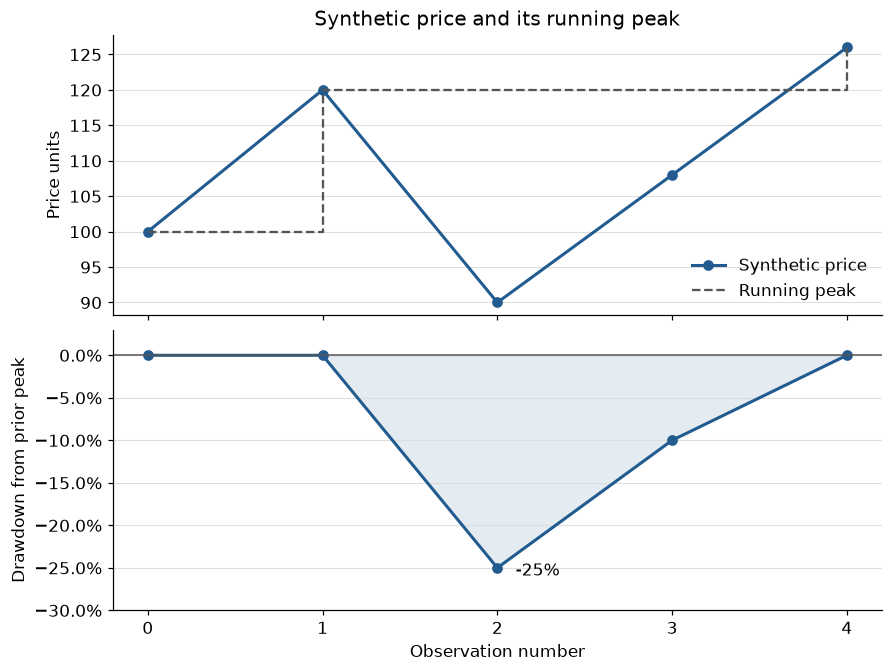

In [3]:
observations = tuple(range(len(prices)))
peaks = tuple(max(prices[: index + 1]) for index in observations)
fig, (price_ax, loss_ax) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, layout="constrained")
price_ax.plot(
    observations, prices, color="#215b8f", marker="o", linewidth=2, label="Synthetic price"
)
price_ax.step(
    observations,
    peaks,
    where="post",
    color="#555555",
    linestyle="--",
    linewidth=1.5,
    label="Running peak",
)
price_ax.set(ylabel="Price units", title="Synthetic price and its running peak")
price_ax.legend(loc="lower right", frameon=False)
loss_ax.plot(observations, underwater, color="#215b8f", marker="o", linewidth=2)
loss_ax.fill_between(observations, underwater, 0, color="#215b8f", alpha=0.12)
loss_ax.axhline(0, color="#555555", linewidth=1)
loss_ax.yaxis.set_major_formatter(PercentFormatter(1.0))
loss_ax.set(
    xticks=observations,
    xlabel="Observation number",
    ylabel="Drawdown from prior peak",
    ylim=(-0.30, 0.03),
)
loss_ax.annotate("-25%", (2, -0.25), xytext=(12, -5), textcoords="offset points")
for axis in (price_ax, loss_ax):
    axis.grid(axis="y", color="#dedede", linewidth=0.7)
plt.show()

The final +26% return and the -25% maximum drawdown coexist. One compares
endpoints; the other searches the whole observed path. Drawdown only sees the
supplied observations, so a daily-close series cannot reveal an intraday fall.

## Measure variation around the mean

Now use a separate three-period example with returns $1\%,-1\%,2\%$. First take
the arithmetic mean: add the decimals and divide by three.

$$\bar r=\frac{0.01-0.01+0.02}{3}=0.006666\ldots.$$

The bar means average. Each return differs from that average. Squaring the
differences makes both positive and negative deviations contribute positively.
For a sample, add those squares and divide by $n-1$, where $n$ is the number of
returns. We use $n-1$ because the mean was estimated from these same values;
the deviations must sum to zero, leaving one fewer freely varying deviation.

$$s^2=\frac{\sum_{t=1}^n(r_t-\bar r)^2}{n-1}
=\frac{0.000466666\ldots}{2}=0.000233333\ldots.$$

This is the **sample variance**. Taking its square root gives the **sample
standard deviation**, about $0.015275$, or 1.5275% per observation. That standard
deviation is the volatility measure used here. Squaring then taking a square
root restores the original return units.

In [4]:
small_prices = (100.0, 101.0, 99.99, 101.9898)
small_returns = simple_returns(small_prices)
per_observation = annualized_volatility(small_returns, periods_per_year=1, ddof=1)
print("Synthetic simple returns:", tuple(round(value, 6) for value in small_returns))
print(f"Sample standard deviation per observation: {per_observation:.4%}")
assert math.isclose(per_observation, math.sqrt(7 / 30000), abs_tol=1e-14)

Synthetic simple returns: (0.01, -0.01, 0.02)
Sample standard deviation per observation: 1.5275%


## Make the time convention explicit

To express a daily standard deviation on a conventional annual scale, this
package multiplies by the square root of the specified number of observations
per year, $m$:

$$\sigma_{\mathrm{annual}}=s\sqrt m.$$

The rule comes from adding variances of uncorrelated increments with a common
variance, then taking the square root. When applied to simple returns it is a
scaling convention, not the exact standard deviation of compounded annual
returns. Serial dependence or changing variance can make the convention
misleading. It is not a promise of future risk.

Here we explicitly choose 252 observations per year. This is a supplied
convention, not a fact inferred from timestamps or a guarantee that any series
has 252 trading days. Weekly, monthly, irregular, and mixed-frequency series
need their own justified treatment. Three synthetic returns are too few to
support a dependable market-risk estimate.

In [5]:
annual = annualized_volatility(small_returns, periods_per_year=252, ddof=1)
population_scaled = annualized_volatility(small_returns, periods_per_year=252, ddof=0)
print(f"Sample convention (ddof=1), annualized: {annual:.4%}")
print(f"Population convention (ddof=0), annualized: {population_scaled:.4%}")
assert math.isclose(annual, math.sqrt(7 / 30000) * math.sqrt(252), abs_tol=1e-13)
assert math.isclose(population_scaled / annual, math.sqrt(2 / 3), abs_tol=1e-13)

Sample convention (ddof=1), annualized: 24.2487%
Population convention (ddof=0), annualized: 19.7990%


The sample convention gives about 24.2487% annually. `ddof` means degrees of
freedom removed: `1` divides the squared deviations by $n-1$; `0` divides by
$n$ and describes the supplied values as the whole population. State the choice
when comparing results. Neither choice fixes an unrepresentative input sample.

**Independent attempt.** A new path is $80,100,90,99$. Choose its final drawdown:
(A) $+23.75\%$, (B) $-1\%$, or (C) $-10\%$. Is that also its maximum drawdown?

**Worked comparison:** B is the final drawdown: the peak already reached is 100,
so $99/100-1=-1\%$. The maximum drawdown was -10% at 90. A is the first-to-last
return, $99/80-1=23.75\%$; C is the earlier worst drawdown. The distinction
requires retaining the path, not just the final value.

**A different boundary case:** for repeated prices $50,50,50$, choose volatility:
(A) zero, (B) undefined, or (C) 50%. A is correct: both returns are zero, their
deviations from the zero mean are zero, and two returns are enough for `ddof=1`.
With only one return, the sample denominator would be zero and the function
rejects the calculation instead of reporting a fabricated zero.

In [6]:
fresh_prices = (80.0, 100.0, 90.0, 99.0)
assert math.isclose(drawdowns(fresh_prices)[-1], -0.01, abs_tol=1e-14)
assert math.isclose(maximum_drawdown(fresh_prices), -0.10, abs_tol=1e-14)
flat_returns = simple_returns((50.0, 50.0, 50.0))
assert annualized_volatility(flat_returns, periods_per_year=252, ddof=1) == 0.0
try:
    annualized_volatility((0.01,), periods_per_year=252, ddof=1)
except ValueError as error:
    print("Insufficient sample rejected:", error)
else:
    raise AssertionError("One return cannot define a sample standard deviation")
print("Fresh path, flat path, and insufficient-sample checks passed.")

Insufficient sample rejected: returns requires at least 2 observations
Fresh path, flat path, and insufficient-sample checks passed.


## Next steps

Use the [learning guide](../docs/learning-guide.md) to run the full synthetic-CSV
example. Use [mathematical conventions](../docs/mathematics.md) before supplying
your own series. Volatility and drawdown describe different features of a path;
neither by itself gives a complete account of investment risk. These notebooks
are authored tutorials with checked calculations, not learner-validated courses.